# Ephemeris-Aided Pairwise Fractional-DD Graph Detector
## Authentic, Fully Spoofed, and Mixed-Tracking Experiments

This notebook uses the notation of the accompanying journal throughout. Its pairwise decision rule is

$$
C_{ij}^{\mathrm{DD}}\leq\tau_c
\quad\land\quad
C_{ij}^{\mathrm{eph}}\geq\tau_e
\quad\Longrightarrow\quad
(i,j)\in\mathcal E_I .
$$

Each tracked PRN is a vertex in $\mathcal V$. The measured fractional-DD collapse statistic $C_{ij}^{\mathrm{DD}}$ and the ephemeris-predicted fractional-DD magnitude $C_{ij}^{\mathrm{eph}}$ are both evaluated in carrier cycles. Informative edges $\mathcal E_I$ generate candidate components; auxiliary collapse edges $\mathcal E_A$ support the complete internal validation.

The same fixed thresholds and label-free graph algorithm are used for all three recordings. Known signal identities are used only in the final post-hoc evaluation and representative-trace selection.

## 1. Pairwise reasoning before graph construction

For every eligible pair $(i,j)\in\mathcal P$, the method asks:

1. Does the measured fractional-DD statistic collapse, $C_{ij}^{\mathrm{DD}}\leq\tau_c$?
2. Does the claimed ephemeris geometry predict a non-collapsed signature, $C_{ij}^{\mathrm{eph}}\geq\tau_e$?

The journal's categorical pair relation is

| $M_{ij}$ | Measured statistic | Ephemeris-predicted statistic | Interpretation |
|---:|---|---|---|
| 2 | $C_{ij}^{\mathrm{DD}}\leq\tau_c$ | $C_{ij}^{\mathrm{eph}}\geq\tau_e$ | Informative edge $(i,j)\in\mathcal E_I$ |
| 1 | $C_{ij}^{\mathrm{DD}}\leq\tau_c$ | $C_{ij}^{\mathrm{eph}}<\tau_e$ | Auxiliary edge $(i,j)\in\mathcal E_A$ |
| 0 | $C_{ij}^{\mathrm{DD}}>\tau_c$ | either | No collapse edge |
| $\varnothing$ | insufficient data | insufficient data | Pair unavailable, not negative evidence |

Thus $M_{ij}=0$ means that this pair does not exhibit the common projected-direction signature expected from a single physical transmitter. It does not independently prove that either signal is authentic.

In [1]:
from itertools import combinations
from pathlib import Path
import importlib

from IPython.display import display
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import seaborn as sns

import aoa_pipeline
import graph_component_classifier
importlib.reload(aoa_pipeline)
importlib.reload(graph_component_classifier)

from aoa_pipeline import (
    DatasetConfig,
    compute_ephemeris_predicted_pair_separation_cycles,
    run_dataset,
    wrap_cycles,
)
from graph_component_classifier import (
    ComponentClassifierConfig,
    EvidenceState,
    classify_common_source_components,
)

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 150)
PUBLICATION_FONT_SIZE_PT = 10.0
PUBLICATION_TITLE_SIZE_PT = 10.5
PUBLICATION_PANEL_TITLE_SIZE_PT = 9.5
PUBLICATION_SMALL_SIZE_PT = 8.0
FULL_WIDTH_FIGURE_IN = 7.2

sns.set_theme(style="whitegrid", context="paper", font="serif")
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": PUBLICATION_FONT_SIZE_PT,
    "axes.titlesize": PUBLICATION_PANEL_TITLE_SIZE_PT,
    "axes.labelsize": PUBLICATION_FONT_SIZE_PT,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "legend.fontsize": PUBLICATION_SMALL_SIZE_PT,
    "figure.titlesize": PUBLICATION_TITLE_SIZE_PT,
    "savefig.dpi": 300,
})

## 2. One fixed configuration for three scenarios

The journal denotes the baseline-to-wavelength ratio by

$$
\beta=\frac{D}{\lambda}=1,
$$

where $D$ is the antenna separation and $\lambda$ is the GPS L1 carrier wavelength.

The fixed decision thresholds are

$$
\tau_c=0.03\ \text{cycles},\qquad
\tau_e=0.05\ \text{cycles},\qquad
0\leq\tau_c<\tau_e<0.5.
$$

$\tau_c$ bounds measured fractional-DD collapse. $\tau_e$ requires an independently predicted non-collapsed ephemeris signature. Both are expressed in carrier cycles and are unchanged across all recordings.

In [2]:
OUTPUT_DIR = Path("outputs/aoa_paper/three_scenario_graph_classifier")
FIGURE_EXPORT_DIR = Path.home() / "Desktop"
FIGURE_EXPORT_FORMATS = ("png", "eps", "pdf", "svg")
SAVE_OUTPUTS = True
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_EXPORT_DIR.mkdir(parents=True, exist_ok=True)

def export_figure(fig, stem):
    """Export at final manuscript size without downstream scaling."""
    exported = []
    for directory in (OUTPUT_DIR, FIGURE_EXPORT_DIR):
        directory.mkdir(parents=True, exist_ok=True)
        for extension in FIGURE_EXPORT_FORMATS:
            path = directory / f"{stem}.{extension}"
            fig.savefig(
                path,
                format=extension,
                dpi=300,
                bbox_inches="tight",
                pad_inches=0.04,
                facecolor="white",
            )
            if directory == FIGURE_EXPORT_DIR:
                exported.append(path)
    return tuple(exported)

BASELINE_OVER_WAVELENGTH = 1.0
FRACTIONAL_DD_COLLAPSE_THRESHOLD_CYCLES = 0.03
EPHEMERIS_FRACTIONAL_DD_NONCOLLAPSE_THRESHOLD_CYCLES = 0.05
MIN_TARGET_EPOCHS = 20
MIN_PAIR_EPOCHS = 10
COMPONENT_CLASSIFIER_CONFIG = ComponentClassifierConfig(
    fractional_dd_collapse_threshold_cycles=FRACTIONAL_DD_COLLAPSE_THRESHOLD_CYCLES,
    ephemeris_predicted_separation_threshold_cycles=EPHEMERIS_FRACTIONAL_DD_NONCOLLAPSE_THRESHOLD_CYCLES,
    min_pair_epochs=MIN_PAIR_EPOCHS,
    min_observed_pair_coverage=1.0,
    min_collapse_fraction=1.0,
)

SCENARIO_SPECS = {
    "Authentic": {
        "receiver1": Path("dataset/Authentic/raw_data_1.ubx"),
        "receiver2": Path("dataset/Authentic/raw_data_2.ubx"),
        "start_index": 0,
        "length": 120,
    },
    "Full spoof": {
        "receiver1": Path("dataset/SP-2025-04-24/raw_data_1.ubx"),
        "receiver2": Path("dataset/SP-2025-04-24/raw_data_2.ubx"),
        "start_index": 0,
        "length": 120,
    },
    "Mixed tracking": {
        "receiver1": Path("dataset/sp-partial-19-06/18-06/COM3___9600_260618_095042.ubx"),
        "receiver2": Path("dataset/sp-partial-19-06/18-06/COM4___9600_260618_095054.ubx"),
        "start_index": 0,
        "length": 34,
    },
}

display(pd.DataFrame([
    {
        "scenario": name,
        "receiver1": str(spec["receiver1"]),
        "receiver2": str(spec["receiver2"]),
        "start_index": spec["start_index"],
        "analysis_epochs": spec["length"],
        "beta_D_over_lambda": BASELINE_OVER_WAVELENGTH,
        "tau_c_cycles": FRACTIONAL_DD_COLLAPSE_THRESHOLD_CYCLES,
        "tau_e_cycles": EPHEMERIS_FRACTIONAL_DD_NONCOLLAPSE_THRESHOLD_CYCLES,
    }
    for name, spec in SCENARIO_SPECS.items()
]))

,scenario,receiver1,receiver2,start_index,analysis_epochs,beta_D_over_lambda,tau_c_cycles,tau_e_cycles
0,Authentic,dataset/Authentic/raw_data_1.ubx,dataset/Authentic/raw_data_2.ubx,0,120,1.0,0.03,0.05
1,Full spoof,dataset/SP-2025-04-24/raw_data_1.ubx,dataset/SP-2025-04-24/raw_data_2.ubx,0,120,1.0,0.03,0.05
2,Mixed tracking,dataset/sp-partial-19-06/18-06/COM3___9600_260...,dataset/sp-partial-19-06/18-06/COM4___9600_260...,0,34,1.0,0.03,0.05


## 3. Carrier-phase pairwise fractional-DD observable

Following the journal, $\phi_{i,k}^{(m)}$ is the carrier-phase observation of signal $i$ at receiver $m\in\{1,2\}$ and epoch $k$, expressed in metres. The inter-receiver single difference is

$$
\Delta\phi_{i,k}=\phi_{i,k}^{(1)}-\phi_{i,k}^{(2)}.
$$

For signals $i$ and $j$, the carrier-phase double difference is

$$
\nabla\Delta\phi_{ij,k}=\Delta\phi_{i,k}-\Delta\phi_{j,k}.
$$

Its normalized value in carrier cycles is

$$
y_{ij,k}=\frac{\nabla\Delta\phi_{ij,k}}{\lambda}
=\beta(\mu_{i,k}-\mu_{j,k})+\nabla\Delta N_{ij}+\nu_{ij,k}.
$$

With the centred fractional operator

$$
\operatorname{wrap}(x)=x-\operatorname{round}(x),\qquad
\operatorname{wrap}(x)\in[-0.5,0.5),
$$

the measured pairwise fractional-DD observable is

$$
\Phi_{ij,k}^{\mathrm{DD}}=\operatorname{wrap}(y_{ij,k}).
$$

The implementation stores $\Delta\phi_{i,k}/\lambda$ in `single_difference_cycles` using the journal order `rx1-rx2`; subtracting the two stored columns therefore produces $y_{ij,k}$ before wrapping. No fixed reference satellite is selected.

## 4. Measured collapse and ephemeris-predicted signature

For pair $(i,j)$, let

$$
\mathcal K_{ij}
=\{k:\text{valid carrier-phase observations of }i\text{ and }j
\text{ are available at both receivers}\}.
$$

The journal's measured collapse statistic is

$$
C_{ij}^{\mathrm{DD}}
=\operatorname{median}_{k\in\mathcal K_{ij}}
\left|\Phi_{ij,k}^{\mathrm{DD}}\right|.
$$

The pair is retained only if $|\mathcal K_{ij}|\geq K_{\min}$ and is measured-collapsed when

$$
C_{ij}^{\mathrm{DD}}\leq\tau_c.
$$

Ephemeris supplies the claimed line-of-sight vector $\mathbf u_{i,k}^{\mathrm{eph}}$. With baseline unit vector $\widehat{\mathbf b}$,

$$
\mu_{i,k}^{\mathrm{eph}}
=\widehat{\mathbf b}^{\,T}\mathbf u_{i,k}^{\mathrm{eph}}
=\cos\!\left(\alpha_{i,k}^{\mathrm{eph}}\right),
$$

$$
\Delta\mu_{ij,k}^{\mathrm{eph}}
=\mu_{i,k}^{\mathrm{eph}}-\mu_{j,k}^{\mathrm{eph}},
\qquad
y_{ij,k}^{\mathrm{eph}}
=\beta\Delta\mu_{ij,k}^{\mathrm{eph}},
$$

and the ephemeris-predicted fractional-DD signature is

$$
\Phi_{ij,k}^{\mathrm{eph}}
=\operatorname{wrap}\!\left[
\beta\left(\mu_{i,k}^{\mathrm{eph}}-\mu_{j,k}^{\mathrm{eph}}\right)
\right].
$$

Using the same epoch set $\mathcal K_{ij}$,

$$
C_{ij}^{\mathrm{eph}}
=\operatorname{median}_{k\in\mathcal K_{ij}}
\left|\Phi_{ij,k}^{\mathrm{eph}}\right|.
$$

The predicted signature is non-collapsed when $C_{ij}^{\mathrm{eph}}\geq\tau_e$. The absolute angular separation $|\alpha_{i,k}^{\mathrm{eph}}-\alpha_{j,k}^{\mathrm{eph}}|$ remains a reporting quantity only; it is not a decision variable.

## 5. Edge-labelled graph construction

The journal represents the pairwise statistics by

$$
\mathcal G=(\mathcal V,\mathcal E_I,\mathcal E_A),
$$

where $\mathcal V$ is the set of analyzable tracked signals and

$$
(i,j)\in\mathcal P
\quad\Longleftrightarrow\quad
|\mathcal K_{ij}|\geq K_{\min}
$$

defines the eligible-pair set. For eligible pairs,

$$
B_{ij}=\mathbb I\!\left(C_{ij}^{\mathrm{DD}}\leq\tau_c\right),
\qquad
G_{ij}=\mathbb I\!\left(C_{ij}^{\mathrm{eph}}\geq\tau_e\right).
$$

The categorical relation is

$$
M_{ij}=
\begin{cases}
2,&B_{ij}=1,\ G_{ij}=1,\\
1,&B_{ij}=1,\ G_{ij}=0,\\
0,&B_{ij}=0,\\
\varnothing,&(i,j)\notin\mathcal P.
\end{cases}
$$

The informative, auxiliary, and complete collapse edge sets are

$$
\mathcal E_I
=\{(i,j)\in\mathcal P:C_{ij}^{\mathrm{DD}}\leq\tau_c,\
C_{ij}^{\mathrm{eph}}\geq\tau_e\},
$$

$$
\mathcal E_A
=\{(i,j)\in\mathcal P:C_{ij}^{\mathrm{DD}}\leq\tau_c,\
C_{ij}^{\mathrm{eph}}<\tau_e\},
\qquad
\mathcal E_C=\mathcal E_I\cup\mathcal E_A.
$$

Candidate components are the non-singleton connected components $S_1,\ldots,S_{N_c}$ of the informative subgraph

$$
\mathcal G_I=(\mathcal V,\mathcal E_I).
$$

Figures use red solid lines for $\mathcal E_I$, orange dashed lines for $\mathcal E_A$, and no line for $M_{ij}=0$ or unavailable pairs.

## 6. Common-source component validation and decision

For a candidate component $S_n\subseteq\mathcal V$, define all unordered internal pairs and their count by

$$
\mathcal P(S_n)=\{(i,j):i,j\in S_n,\ i<j\},
\qquad
N_p(S_n)=|\mathcal P(S_n)|
=\frac{|S_n|(|S_n|-1)}{2}.
$$

The observation-completeness and collapse-consistency ratios are

$$
q_o(S_n)
=\frac{\sum_{(i,j)\in\mathcal P(S_n)}
\mathbb I\!\left((i,j)\in\mathcal P\right)}
{N_p(S_n)},
$$

$$
q_c(S_n)
=\frac{\sum_{(i,j)\in\mathcal P(S_n)}
\mathbb I\!\left((i,j)\in\mathcal E_C\right)}
{\sum_{(i,j)\in\mathcal P(S_n)}
\mathbb I\!\left((i,j)\in\mathcal P\right)}.
$$

The journal's validation rule is

$$
V(S_n)=
\begin{cases}
1,&|S_n|\geq S_{\min},\ q_o(S_n)=1,\ q_c(S_n)=1,\\
0,&\text{otherwise},
\end{cases}
\qquad S_{\min}=3.
$$

Validated components, assigned common-source vertices, and the signal decision are

$$
\widehat{\mathcal C}=\{S_n:V(S_n)=1\},
\qquad
\widehat{\mathcal V}_{\mathrm{CS}}
=\bigcup_{S_n\in\widehat{\mathcal C}}S_n,
$$

$$
\widehat d_i=
\begin{cases}
1,&i\in\widehat{\mathcal V}_{\mathrm{CS}},\\
0,&i\notin\widehat{\mathcal V}_{\mathrm{CS}}.
\end{cases}
$$

Candidate generation uses only $\mathcal E_I$, but validation uses every internal relation in $\mathcal E_C$. A missing internal pair gives $q_o<1$; an observed non-collapse gives $q_c<1$. A two-vertex informative component is retained only as a pair-level anomaly.

In [3]:
def build_fractional_dd_ephemeris_pair_evidence(
    single_difference_cycles, ephemeris_aoa_deg, nodes, baseline_over_wavelength
):
    """Build both pair metrics from exactly the same jointly valid epochs."""
    single_difference = single_difference_cycles.reindex(columns=nodes)
    ephemeris_aoa = ephemeris_aoa_deg.reindex(
        index=single_difference.index, columns=nodes
    )
    epoch_rows = []
    aggregate_rows = []
    for left_svid, right_svid in combinations(nodes, 2):
        joint = pd.DataFrame({
            "left_single_difference_cycles": single_difference[left_svid],
            "right_single_difference_cycles": single_difference[right_svid],
            "left_ephemeris_aoa_deg": ephemeris_aoa[left_svid],
            "right_ephemeris_aoa_deg": ephemeris_aoa[right_svid],
        }).dropna()
        if joint.empty:
            continue
        joint["fractional_dd_cycles"] = wrap_cycles(
            joint.left_single_difference_cycles
            - joint.right_single_difference_cycles
        )
        joint["fractional_dd_collapse_cycles"] = joint.fractional_dd_cycles.abs()
        joint["ephemeris_aoa_separation_deg"] = (
            joint.left_ephemeris_aoa_deg - joint.right_ephemeris_aoa_deg
        ).abs()
        joint["left_ephemeris_direction_cosine"] = np.cos(
            np.deg2rad(joint.left_ephemeris_aoa_deg)
        )
        joint["right_ephemeris_direction_cosine"] = np.cos(
            np.deg2rad(joint.right_ephemeris_aoa_deg)
        )
        joint["ephemeris_predicted_pair_cycles"] = baseline_over_wavelength * (
            joint.left_ephemeris_direction_cosine
            - joint.right_ephemeris_direction_cosine
        )
        joint["ephemeris_predicted_pair_cycles_wrapped"] = wrap_cycles(
            joint.ephemeris_predicted_pair_cycles
        )
        joint["ephemeris_predicted_pair_separation_cycles"] = (
            compute_ephemeris_predicted_pair_separation_cycles(
                joint.left_ephemeris_aoa_deg,
                joint.right_ephemeris_aoa_deg,
                baseline_over_wavelength=baseline_over_wavelength,
            )
        )
        joint = joint.reset_index().rename(
            columns={joint.index.name or "index": "epoch_index"}
        )
        joint.insert(1, "left_svid", int(left_svid))
        joint.insert(2, "right_svid", int(right_svid))
        epoch_rows.append(joint)
        aggregate_rows.append({
            "pair": f"PRN {left_svid}–PRN {right_svid}",
            "left_svid": int(left_svid),
            "right_svid": int(right_svid),
            "median_fractional_dd_collapse_cycles": float(
                joint.fractional_dd_collapse_cycles.median()
            ),
            "median_ephemeris_predicted_pair_separation_cycles": float(
                joint.ephemeris_predicted_pair_separation_cycles.median()
            ),
            "median_ephemeris_aoa_separation_deg": float(
                joint.ephemeris_aoa_separation_deg.median()
            ),
            "epoch_count": len(joint),
        })
    epoch_columns = [
        "epoch_index", "left_svid", "right_svid",
        "left_single_difference_cycles", "right_single_difference_cycles",
        "left_ephemeris_aoa_deg", "right_ephemeris_aoa_deg",
        "fractional_dd_cycles", "fractional_dd_collapse_cycles",
        "ephemeris_aoa_separation_deg",
        "left_ephemeris_direction_cosine", "right_ephemeris_direction_cosine",
        "ephemeris_predicted_pair_cycles",
        "ephemeris_predicted_pair_cycles_wrapped",
        "ephemeris_predicted_pair_separation_cycles",
    ]
    aggregate_columns = [
        "pair", "left_svid", "right_svid",
        "median_fractional_dd_collapse_cycles",
        "median_ephemeris_predicted_pair_separation_cycles",
        "median_ephemeris_aoa_separation_deg", "epoch_count",
    ]
    epoch_pairs = (
        pd.concat(epoch_rows, ignore_index=True)
        if epoch_rows else pd.DataFrame(columns=epoch_columns)
    )
    aggregated_pairs = pd.DataFrame(aggregate_rows, columns=aggregate_columns)
    return epoch_pairs, aggregated_pairs

def symmetric_pair_matrix(nodes, pairs, value_column, diagonal=np.nan):
    matrix = pd.DataFrame(np.nan, index=nodes, columns=nodes, dtype=float)
    for row in pairs.itertuples():
        left, right = int(row.left_svid), int(row.right_svid)
        value = float(getattr(row, value_column))
        matrix.loc[left, right] = matrix.loc[right, left] = value
    for node in nodes:
        matrix.loc[node, node] = diagonal
    matrix.index.name = "PRN i"
    matrix.columns.name = "PRN j"
    return matrix

In [4]:
def analyze_scenario(name, spec):
    config = DatasetConfig(
        name=f"three_scenario_graph_classifier/{name.lower().replace(' ', '_')}",
        receiver1_path=spec["receiver1"],
        receiver2_path=spec["receiver2"],
        start_index=spec["start_index"],
        length=spec["length"],
        alpha_r_deg=None,
        reference_svid=None,
        selected_svids=None,
        excluded_reference_svids=None,
        reference_required_svids=None,
        excluded_analysis_svids=None,
        sync_tow_decimals=0,
        use_navpvt_time_correction=True,
        single_difference_order="rx1-rx2",
        navsat_azimuth_bias_deg=0.0,
        baseline_over_wavelength=BASELINE_OVER_WAVELENGTH,
    )
    run = run_dataset(config)
    common_svids = sorted(set(run.single_difference_cycles.columns) & set(run.ephemeris_aoa_deg.columns))
    nodes = [
        int(svid) for svid in common_svids
        if run.single_difference_cycles[svid].notna().sum() >= MIN_TARGET_EPOCHS
        and run.ephemeris_aoa_deg[svid].notna().sum() >= MIN_TARGET_EPOCHS
    ]
    epoch_pairs, aggregated_pairs = build_fractional_dd_ephemeris_pair_evidence(
        run.single_difference_cycles, run.ephemeris_aoa_deg, nodes,
        BASELINE_OVER_WAVELENGTH,
    )
    graph_result = classify_common_source_components(
        nodes, aggregated_pairs, config=COMPONENT_CLASSIFIER_CONFIG
    )
    pairs = graph_result.pair_evidence.merge(
        aggregated_pairs[[
            "left_svid", "right_svid", "median_ephemeris_aoa_separation_deg",
        ]],
        on=["left_svid", "right_svid"],
        how="left",
        validate="one_to_one",
    )
    pairs["relation_code"] = np.select(
        [
            pairs.informative_common_source_edge,
            pairs.fractional_dd_collapsed,
            pairs.observed,
        ],
        [2, 1, 0],
        default=np.nan,
    )
    pairs["specific_node_relation"] = pairs.relation.map({
        "informative_common_source": "M_ij=2: informative edge in E_I",
        "predicted_phase_aliased_collapse": "M_ij=1: auxiliary edge in E_A",
        "noncollapse": "M_ij=0: measured fractional DD not collapsed",
        "missing": "M_ij=empty: pair unavailable",
    })

    components = tuple(graph_result.component_summary.component_svids)
    component_summary = graph_result.component_summary
    validated_components = list(graph_result.corroborated_groups)
    selected_group = tuple(sorted({node for group in validated_components for node in group}))

    scenario_decision = {
        EvidenceState.UNDETERMINED: "Undetermined: insufficient pair coverage",
        EvidenceState.NO_GROUP_EVIDENCE: "No threshold-qualified common-signature group detected",
        EvidenceState.PAIR_ALERTS_ONLY: "Pair-level common-spatial-signature alert(s); not a corroborated group",
        EvidenceState.SINGLE_ALL_NODE_COMPONENT: "All analyzable PRNs form one corroborated common-signature component",
        EvidenceState.SINGLE_SUBSET_COMPONENT: "One strict PRN subset forms a corroborated common-signature component",
        EvidenceState.MULTIPLE_COMPONENTS: "Multiple distinct common-signature components detected",
    }[graph_result.evidence_state]

    node_rows = []
    for node in nodes:
        incident = pairs.loc[pairs.left_svid.eq(node) | pairs.right_svid.eq(node)]
        node_rows.append({
            "svid": node,
            "fractional_dd_collapse_degree": int(incident.fractional_dd_collapsed.sum()),
            "informative_common_source_degree": int(incident.informative_common_source_edge.sum()),
            "predicted_phase_aliased_collapse_degree": int((
                incident.fractional_dd_collapsed & ~incident.predicted_phase_distinguishable
            ).sum()),
            "selected_common_source_member": node in selected_group,
            "graph_evidence_status": graph_result.node_summary.set_index("svid").loc[node, "status"],
        })
    node_summary = pd.DataFrame(node_rows)

    availability_nodes = sorted(set(run.single_difference_cycles.columns) | set(run.ephemeris_aoa_deg.columns))
    availability = pd.DataFrame({
        "svid": availability_nodes,
        "single_difference_epochs": [
            int(run.single_difference_cycles.get(node, pd.Series(dtype=float)).notna().sum()) for node in availability_nodes
        ],
        "ephemeris_epochs": [
            int(run.ephemeris_aoa_deg.get(node, pd.Series(dtype=float)).notna().sum()) for node in availability_nodes
        ],
    })
    availability["eligible"] = availability.svid.isin(nodes)

    return {
        "name": name, "run": run, "epoch_pairs": epoch_pairs, "pairs": pairs,
        "nodes": nodes, "components": components, "component_summary": component_summary,
        "validated_components": validated_components, "selected_group": selected_group,
        "pair_alerts": graph_result.pair_alerts, "evidence_state": graph_result.evidence_state,
        "scenario_decision": scenario_decision, "node_summary": node_summary,
        "availability": availability,
    }

## 7. Run the identical graph algorithm on all datasets

The analysis function receives only observations and the fixed configuration. For each recording it constructs

$$
\mathcal G=(\mathcal V,\mathcal E_I,\mathcal E_A),
\quad
\{S_1,\ldots,S_{N_c}\},
\quad
\widehat{\mathcal C},
\quad
\widehat{\mathcal V}_{\mathrm{CS}},
\quad
\widehat{\mathcal H}.
$$

The candidate components $S_n$ remain separate when interpreting physical sources. Their union $\widehat{\mathcal V}_{\mathrm{CS}}$ is used only to list signals assigned to validated common-source groups.

In [5]:
results = {}
for scenario_name, scenario_spec in SCENARIO_SPECS.items():
    print(f"Running {scenario_name}...")
    results[scenario_name] = analyze_scenario(scenario_name, scenario_spec)
print("All scenarios completed.")

comparison_rows = []
for name, result in results.items():
    pairs = result["pairs"]
    comparison_rows.append({
        "scenario": name,
        "epochs": len(result["run"].epochs),
        "eligible_svids": tuple(result["nodes"]),
        "eligible_satellite_count": len(result["nodes"]),
        "pair_count": len(pairs),
        "baseline_over_wavelength": BASELINE_OVER_WAVELENGTH,
        "fractional_dd_threshold_cycles": FRACTIONAL_DD_COLLAPSE_THRESHOLD_CYCLES,
        "ephemeris_predicted_separation_threshold_cycles": EPHEMERIS_FRACTIONAL_DD_NONCOLLAPSE_THRESHOLD_CYCLES,
        "fractional_dd_collapse_edge_count": int(pairs.fractional_dd_collapsed.sum()),
        "informative_edge_count": int(pairs.informative_common_source_edge.sum()),
        "validated_components": tuple(result["validated_components"]),
        "selected_group": result["selected_group"],
        "scenario_decision": result["scenario_decision"],
    })
scenario_comparison = pd.DataFrame(comparison_rows)
display(scenario_comparison)

Running Authentic...


Running Full spoof...


Running Mixed tracking...


All scenarios completed.


,scenario,epochs,eligible_svids,eligible_satellite_count,pair_count,baseline_over_wavelength,fractional_dd_threshold_cycles,ephemeris_predicted_separation_threshold_cycles,fractional_dd_collapse_edge_count,informative_edge_count,validated_components,selected_group,scenario_decision
0,Authentic,120,"(5, 10, 15, 18, 23, 24, 32)",7,21,1.0,0.03,0.05,0,0,(),(),No threshold-qualified common-signature group ...
1,Full spoof,120,"(11, 12, 13, 15, 18, 20, 23, 24, 29, 30)",10,45,1.0,0.03,0.05,45,40,"((11, 12, 13, 15, 18, 20, 23, 24, 29, 30),)","(11, 12, 13, 15, 18, 20, 23, 24, 29, 30)",All analyzable PRNs form one corroborated comm...
2,Mixed tracking,34,"(6, 9, 10, 11, 12, 15, 18, 20, 23, 24, 32)",11,55,1.0,0.03,0.05,6,5,"((6, 9, 11, 20),)","(6, 9, 11, 20)",One strict PRN subset forms a corroborated com...


## 8. Reading each graph and heatmap

For each recording, the four-panel visualization contains:

1. **$C_{ij}^{\mathrm{DD}}$ heatmap (cycles):** small values indicate measured fractional-DD collapse;
2. **$C_{ij}^{\mathrm{eph}}$ heatmap (cycles):** large values indicate an ephemeris-predicted non-collapsed signature after baseline projection and modulo-one wrapping;
3. **$M_{ij}$ heatmap:** 2 = informative edge, 1 = auxiliary edge, 0 = no collapse edge;
4. **Graph $\mathcal G$:** the same $\mathcal E_I$ and $\mathcal E_A$ relations drawn between PRN vertices.

A red vertex belongs to $\widehat{\mathcal V}_{\mathrm{CS}}$. A blue vertex is not assigned to a validated common-source group; this is not independent proof of authenticity. The node summary reports incident $\mathcal E_C$, $\mathcal E_I$, and $\mathcal E_A$ counts as descriptive diagnostics.

In [6]:
def graph_legend_handles(scale=1.0):
    return [
        Line2D([0], [0], marker="o", color="none", markerfacecolor="#fb6a4a", markeredgecolor="black", markersize=6.5 * scale, label="Selected common-source node"),
        Line2D([0], [0], marker="o", color="none", markerfacecolor="#6baed6", markeredgecolor="black", markersize=6.5 * scale, label="Other node"),
        Line2D([0], [0], color="#de2d26", lw=1.5 * scale, label=r"$M_{ij}=2$: informative edge $\mathcal{E}_I$"),
        Line2D([0], [0], color="#f16913", lw=1.3 * scale, ls="--", label=r"$M_{ij}=1$: auxiliary edge $\mathcal{E}_A$"),
    ]

def graph_panel_title(result, compact=False):
    scenario_summary = {
        "Authentic": ("Authentic", "No validated component"),
        "Full spoof": ("Fully spoofed", "One all-PRN component"),
        "Mixed tracking": ("Mixed tracking", r"Component $\{6,9,11,20\}$"),
    }
    scenario, summary = scenario_summary[result["name"]]
    prefix = "" if compact else r"Graph $\mathcal{G}$ - "
    return f"{prefix}{scenario}\n{summary}"

def draw_relation_graph(result, ax, show_edge_labels=True, show_legend=True, compact=False):
    nodes = result["nodes"]
    selected = set(result["selected_group"])
    selected_nodes = sorted(selected)
    other_nodes = [node for node in nodes if node not in selected]
    if selected_nodes and other_nodes:
        selected_angles = np.pi / 2 - np.arange(len(selected_nodes)) * 2 * np.pi / len(selected_nodes)
        positions = {
            node: (-0.45 + 0.55 * np.cos(angle), 0.55 * np.sin(angle))
            for node, angle in zip(selected_nodes, selected_angles)
        }
        other_y = np.linspace(1.0, -1.0, len(other_nodes))
        positions.update({node: (0.95, y) for node, y in zip(other_nodes, other_y)})
    else:
        angles = np.pi / 2 - np.arange(len(nodes)) * 2 * np.pi / max(len(nodes), 1)
        positions = {node: (np.cos(angle), np.sin(angle)) for node, angle in zip(nodes, angles)}
    collapsed = result["pairs"].loc[result["pairs"].fractional_dd_collapsed]
    label_edges = show_edge_labels and len(collapsed) <= 4
    for row in collapsed.itertuples():
        left, right = int(row.left_svid), int(row.right_svid)
        x = [positions[left][0], positions[right][0]]
        y = [positions[left][1], positions[right][1]]
        informative = bool(row.informative_common_source_edge)
        ax.plot(
            x, y,
            color=(("#ef9a9a" if informative else "#fdd0a2") if len(collapsed) > 20
                   else ("#de2d26" if informative else "#f16913")),
            lw=(1.35 if informative else 1.15) if compact else (1.6 if informative else 1.35),
            ls="-" if informative else "--",
            alpha=1.0,
            zorder=1,
        )
        if label_edges:
            dx, dy = x[1] - x[0], y[1] - y[0]
            edge_length = max(np.hypot(dx, dy), 1e-12)
            label_fraction = 0.35
            mid_x = x[0] + label_fraction * dx
            mid_y = y[0] + label_fraction * dy
            offset_sign = 1 if (left + right) % 2 else -1
            mid_x += offset_sign * 0.055 * (-dy / edge_length)
            mid_y += offset_sign * 0.055 * (dx / edge_length)
            ax.text(
                mid_x, mid_y,
                f"$C^{{\\mathrm{{DD}}}}_{{ij}}$={row.median_fractional_dd_collapse_cycles:.3f} cycles\n"
                f"$C^{{\\mathrm{{eph}}}}_{{ij}}$={row.median_ephemeris_predicted_pair_separation_cycles:.3f} cycles\n"
                f"$|\\alpha_i^{{\\mathrm{{eph}}}}-\\alpha_j^{{\\mathrm{{eph}}}}|$={row.median_ephemeris_aoa_separation_deg:.1f} deg (report only)",
                fontsize=PUBLICATION_SMALL_SIZE_PT, ha="center", va="center",
                bbox={"facecolor": "white", "alpha": 1.0, "edgecolor": "#bdbdbd", "pad": 1},
                zorder=2,
            )
    for node in nodes:
        x, y = positions[node]
        ax.scatter(
            x, y, s=210 if compact else 280,
            color="#fb6a4a" if node in selected else "#6baed6",
            edgecolor="black", linewidth=0.9, zorder=3,
        )
        ax.text(
            x, y, str(node), ha="center", va="center",
            fontsize=7.5 if compact else 8.5, fontweight="bold", zorder=4,
        )
    if show_legend:
        ax.legend(
            handles=graph_legend_handles(), loc="lower center",
            bbox_to_anchor=(0.5, -0.14), fontsize=7.2,
            framealpha=1.0, borderpad=0.35, labelspacing=0.25,
        )
    ax.set_title(
        graph_panel_title(result, compact=compact),
        fontsize=PUBLICATION_PANEL_TITLE_SIZE_PT if not compact else 8.5,
        pad=3,
    )
    ax.set_aspect("equal")
    ax.set_xlim(-1.35, 1.35)
    ax.set_ylim(-1.35, 1.35)
    ax.axis("off")

def plot_scenario_evidence(result):
    nodes = result["nodes"]
    selected = list(result["selected_group"])
    ordered = selected + [node for node in nodes if node not in selected]
    pairs = result["pairs"]
    collapse = symmetric_pair_matrix(nodes, pairs, "median_fractional_dd_collapse_cycles", diagonal=0.0).loc[ordered, ordered]
    predicted_separation = symmetric_pair_matrix(nodes, pairs, "median_ephemeris_predicted_pair_separation_cycles", diagonal=0.0).loc[ordered, ordered]
    relation = symmetric_pair_matrix(nodes, pairs, "relation_code", diagonal=np.nan).loc[ordered, ordered]

    # Preserve the original matrix presentation and enlarge only surrounding publication text.
    fig, axes = plt.subplots(2, 2, figsize=(12.0, 10.0))
    heatmap_annotation = {"fontsize": 8.5}
    evidence_title_size = 16.0
    evidence_axis_label_size = 14.0
    evidence_tick_size = 11.0
    evidence_legend_size = 12.3
    sns.heatmap(
        collapse, annot=True, annot_kws=heatmap_annotation, fmt=".3f", cmap="mako_r",
        vmin=0, vmax=0.5, square=True, linewidths=0.4, ax=axes[0, 0],
    )
    axes[0, 0].set_title(
        r"$C^{\mathrm{DD}}_{ij}$: measured fractional-DD collapse (cycles)",
        fontsize=evidence_title_size, pad=5,
    )
    sns.heatmap(
        predicted_separation, annot=True, annot_kws=heatmap_annotation, fmt=".3f",
        cmap="viridis", vmin=0, vmax=0.5, square=True, linewidths=0.4, ax=axes[0, 1],
    )
    axes[0, 1].set_title(
        r"$C^{\mathrm{eph}}_{ij}$: ephemeris-predicted fractional-DD magnitude (cycles)",
        fontsize=evidence_title_size, pad=5,
    )
    relation_cmap = ListedColormap(["#d9d9d9", "#fdae6b", "#de2d26"])
    relation_ax = sns.heatmap(
        relation, annot=True, annot_kws=heatmap_annotation, fmt=".0f",
        cmap=relation_cmap, vmin=0, vmax=2, square=True, linewidths=0.4,
        cbar_kws={"ticks": [0.33, 1.0, 1.67]}, ax=axes[1, 0],
    )
    relation_ax.collections[0].colorbar.set_ticklabels([r"$M_{ij}=0$", r"$M_{ij}=1$", r"$M_{ij}=2$"])
    axes[1, 0].set_title(
        r"$M_{ij}$: categorical pair relation",
        fontsize=evidence_title_size, pad=5,
    )
    draw_relation_graph(result, axes[1, 1], show_legend=False)
    axes[1, 1].title.set_fontsize(evidence_title_size)
    for text in axes[1, 1].texts:
        text.set_fontsize(11.0)
    for matrix_ax in (axes[0, 0], axes[0, 1], axes[1, 0]):
        matrix_ax.tick_params(axis="both", labelsize=evidence_tick_size)
        matrix_ax.xaxis.label.set_size(evidence_axis_label_size)
        matrix_ax.yaxis.label.set_size(evidence_axis_label_size)
        matrix_ax.collections[0].colorbar.ax.tick_params(labelsize=evidence_tick_size)
    if selected and len(selected) < len(nodes):
        boundary = len(selected)
        for ax in axes[0, 0], axes[0, 1], axes[1, 0]:
            ax.axhline(boundary, color="white", lw=3)
            ax.axvline(boundary, color="white", lw=3)
    fig.legend(
        handles=graph_legend_handles(scale=1.6), loc="lower center", ncol=2,
        bbox_to_anchor=(0.5, 0.005), fontsize=evidence_legend_size,
        frameon=True, framealpha=1.0, borderpad=0.45, labelspacing=0.35,
    )
    fig.tight_layout(rect=(0.0, 0.10, 1.0, 1.0), pad=1.0)
    if SAVE_OUTPUTS:
        stem = result["name"].lower().replace(" ", "_") + "_graph_evidence"
        export_figure(fig, stem)
    display(fig)
    plt.close(fig)

# 9. Scenario A - Authentic-only recording

For distinct authentic sources, geometrically distinguishable claimed directions should not repeatedly produce measured fractional-DD collapse. The expected journal-level decision is

$$
\widehat{\mathcal C}=\varnothing
\quad\Longrightarrow\quad
\widehat{\mathcal H}=\mathcal H_0.
$$

No threshold-qualified common-signature group detected
Selected group: none
Satellite availability and eligibility


,svid,single_difference_epochs,ephemeris_epochs,eligible
0,5,117,120,True
1,10,119,120,True
2,12,0,120,False
3,15,120,120,True
4,18,50,120,True
5,23,120,120,True
6,24,120,120,True
7,25,0,120,False
8,27,0,120,False
9,28,0,120,False


Node relations and graph degree


,svid,fractional_dd_collapse_degree,informative_common_source_degree,predicted_phase_aliased_collapse_degree,selected_common_source_member,graph_evidence_status
0,5,0,0,0,False,not_assigned_to_detected_group
1,10,0,0,0,False,not_assigned_to_detected_group
2,15,0,0,0,False,not_assigned_to_detected_group
3,18,0,0,0,False,not_assigned_to_detected_group
4,23,0,0,0,False,not_assigned_to_detected_group
5,24,0,0,0,False,not_assigned_to_detected_group
6,32,0,0,0,False,not_assigned_to_detected_group


Connected-component validation


,component_id,component_svids,component_size,possible_pair_count,observed_pair_count,observed_pair_coverage,collapse_pair_count,collapse_fraction_observed,informative_pair_count,noncollapse_pair_count,corroborated_common_signature_group,rejection_reasons


All authentic pair relations, sorted by fractional-DD collapse


,pair,median_fractional_dd_collapse_cycles,median_ephemeris_predicted_pair_separation_cycles,median_ephemeris_aoa_separation_deg,relation_code,specific_node_relation,epoch_count
13,PRN 15–PRN 24,0.08401,0.29581,19.55717,0.0,M_ij=0: measured fractional DD not collapsed,120
9,PRN 10–PRN 24,0.08700,0.37884,26.00761,0.0,M_ij=0: measured fractional DD not collapsed,119
7,PRN 10–PRN 18,0.11144,0.08407,57.24310,0.0,M_ij=0: measured fractional DD not collapsed,50
3,PRN 5–PRN 23,0.11928,0.06620,56.70599,0.0,M_ij=0: measured fractional DD not collapsed,117
6,PRN 10–PRN 15,0.15048,0.08303,6.45044,0.0,M_ij=0: measured fractional DD not collapsed,119
1,PRN 5–PRN 15,0.16155,0.06165,57.04174,0.0,M_ij=0: measured fractional DD not collapsed,117
16,PRN 18–PRN 24,0.20158,0.46291,31.23549,0.0,M_ij=0: measured fractional DD not collapsed,50
19,PRN 23–PRN 32,0.23732,0.34140,40.65288,0.0,M_ij=0: measured fractional DD not collapsed,120
4,PRN 5–PRN 24,0.25545,0.35746,37.48456,0.0,M_ij=0: measured fractional DD not collapsed,117
11,PRN 15–PRN 18,0.26091,0.16710,50.79266,0.0,M_ij=0: measured fractional DD not collapsed,50


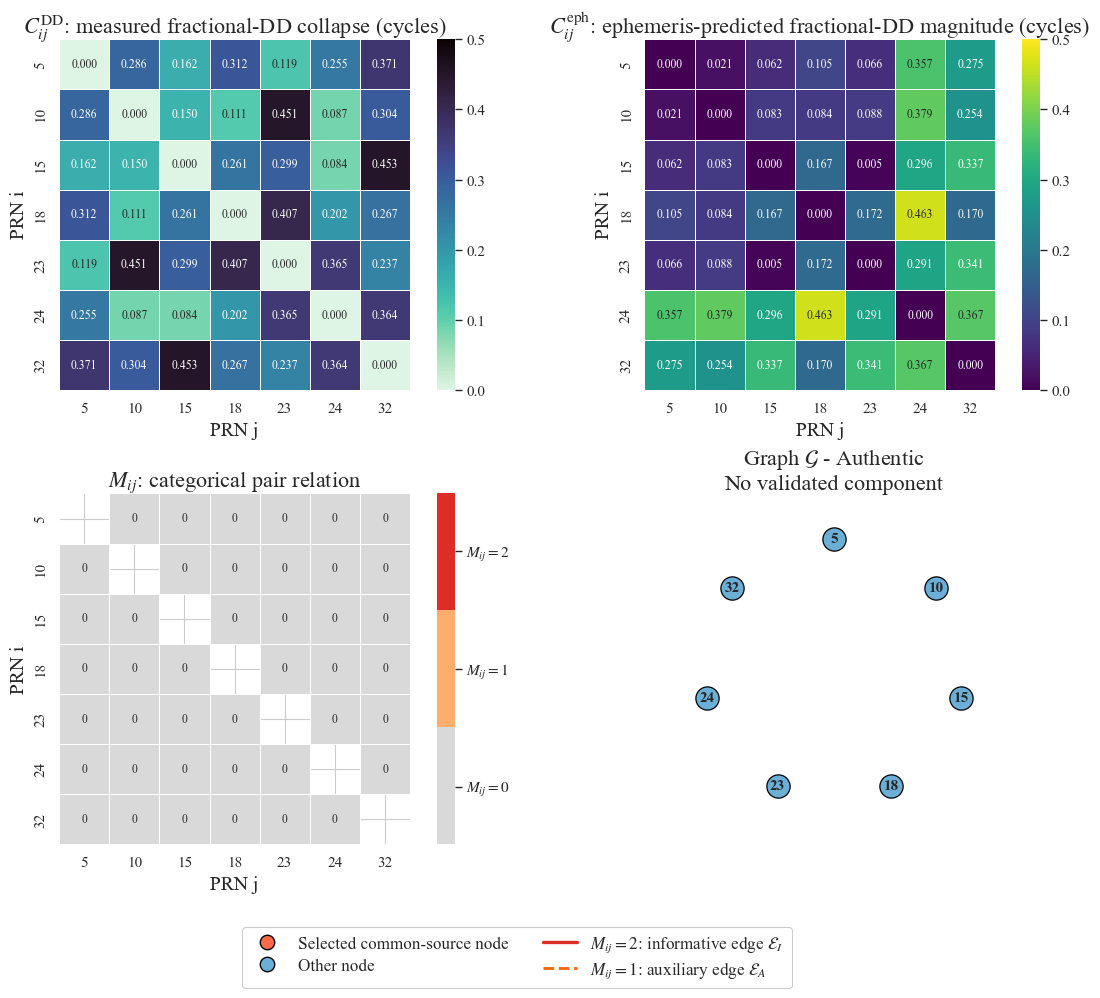

In [7]:
authentic_result = results["Authentic"]
print(authentic_result["scenario_decision"])
print("Selected group:", authentic_result["selected_group"] or "none")
print("Satellite availability and eligibility")
display(authentic_result["availability"])
print("Node relations and graph degree")
display(authentic_result["node_summary"])
print("Connected-component validation")
display(authentic_result["component_summary"].round(5))
print("All authentic pair relations, sorted by fractional-DD collapse")
display(authentic_result["pairs"][[
    "pair", "median_fractional_dd_collapse_cycles",
    "median_ephemeris_predicted_pair_separation_cycles",
    "median_ephemeris_aoa_separation_deg",
    "relation_code", "specific_node_relation", "epoch_count",
]].sort_values("median_fractional_dd_collapse_cycles").round(5))
plot_scenario_evidence(authentic_result)

# 10. Scenario B - Fully spoofed recording

For signals transmitted from approximately the same physical direction,

$$
\mu_{i,k}\simeq\mu_{j,k},
\qquad
\Phi_{ij,k}^{\mathrm{DD}}
\simeq\operatorname{wrap}(\nu_{ij,k})
\simeq0.
$$

Thus every counterfeit pair should satisfy measured collapse. Pairs with $C_{ij}^{\mathrm{eph}}\geq\tau_e$ form informative edges in $\mathcal E_I$; pairs with $C_{ij}^{\mathrm{eph}}<\tau_e$ form auxiliary edges in $\mathcal E_A$.

The expected journal-level decision is

$$
\widehat{\mathcal C}=\{\mathcal V\}
\quad\Longrightarrow\quad
\widehat{\mathcal H}=\mathcal H_F.
$$

All analyzable PRNs form one corroborated common-signature component
Selected group: (11, 12, 13, 15, 18, 20, 23, 24, 29, 30)
Satellite availability and eligibility


,svid,single_difference_epochs,ephemeris_epochs,eligible
0,5,0,120,False
1,11,120,120,True
2,12,120,120,True
3,13,120,120,True
4,15,120,120,True
5,18,120,120,True
6,20,120,120,True
7,23,120,120,True
8,24,120,120,True
9,25,0,120,False


Node relations and graph degree


,svid,fractional_dd_collapse_degree,informative_common_source_degree,predicted_phase_aliased_collapse_degree,selected_common_source_member,graph_evidence_status
0,11,9,8,1,True,corroborated_group_member
1,12,9,7,2,True,corroborated_group_member
2,13,9,8,1,True,corroborated_group_member
3,15,9,7,2,True,corroborated_group_member
4,18,9,9,0,True,corroborated_group_member
5,20,9,8,1,True,corroborated_group_member
6,23,9,9,0,True,corroborated_group_member
7,24,9,9,0,True,corroborated_group_member
8,29,9,7,2,True,corroborated_group_member
9,30,9,8,1,True,corroborated_group_member


Connected-component validation


,component_id,component_svids,component_size,possible_pair_count,observed_pair_count,observed_pair_coverage,collapse_pair_count,collapse_fraction_observed,informative_pair_count,noncollapse_pair_count,corroborated_common_signature_group,rejection_reasons
0,1,"(11, 12, 13, 15, 18, 20, 23, 24, 29, 30)",10,45,45,1.0,45,1.0,40,0,True,()


Every pair relation; orange rows have predicted phase separation below 0.05 cycles


,pair,median_fractional_dd_collapse_cycles,median_ephemeris_predicted_pair_separation_cycles,median_ephemeris_aoa_separation_deg,relation_code,specific_node_relation,epoch_count
17,PRN 13–PRN 15,0.00606,0.39541,23.29149,2.0,M_ij=2: informative edge in E_I,120
24,PRN 15–PRN 18,0.00820,0.25952,47.77249,2.0,M_ij=2: informative edge in E_I,120
22,PRN 13–PRN 29,0.00825,0.37640,22.20248,2.0,M_ij=2: informative edge in E_I,120
18,PRN 13–PRN 18,0.00970,0.34507,24.48100,2.0,M_ij=2: informative edge in E_I,120
1,PRN 11–PRN 13,0.01052,0.24492,44.37142,2.0,M_ij=2: informative edge in E_I,120
2,PRN 11–PRN 15,0.01053,0.35967,21.07992,2.0,M_ij=2: informative edge in E_I,120
33,PRN 18–PRN 29,0.01087,0.27597,46.90216,2.0,M_ij=2: informative edge in E_I,120
27,PRN 15–PRN 24,0.01132,0.10033,64.11428,2.0,M_ij=2: informative edge in E_I,120
26,PRN 15–PRN 23,0.01184,0.21394,12.35342,2.0,M_ij=2: informative edge in E_I,120
7,PRN 11–PRN 29,0.01192,0.36995,21.63507,2.0,M_ij=2: informative edge in E_I,120


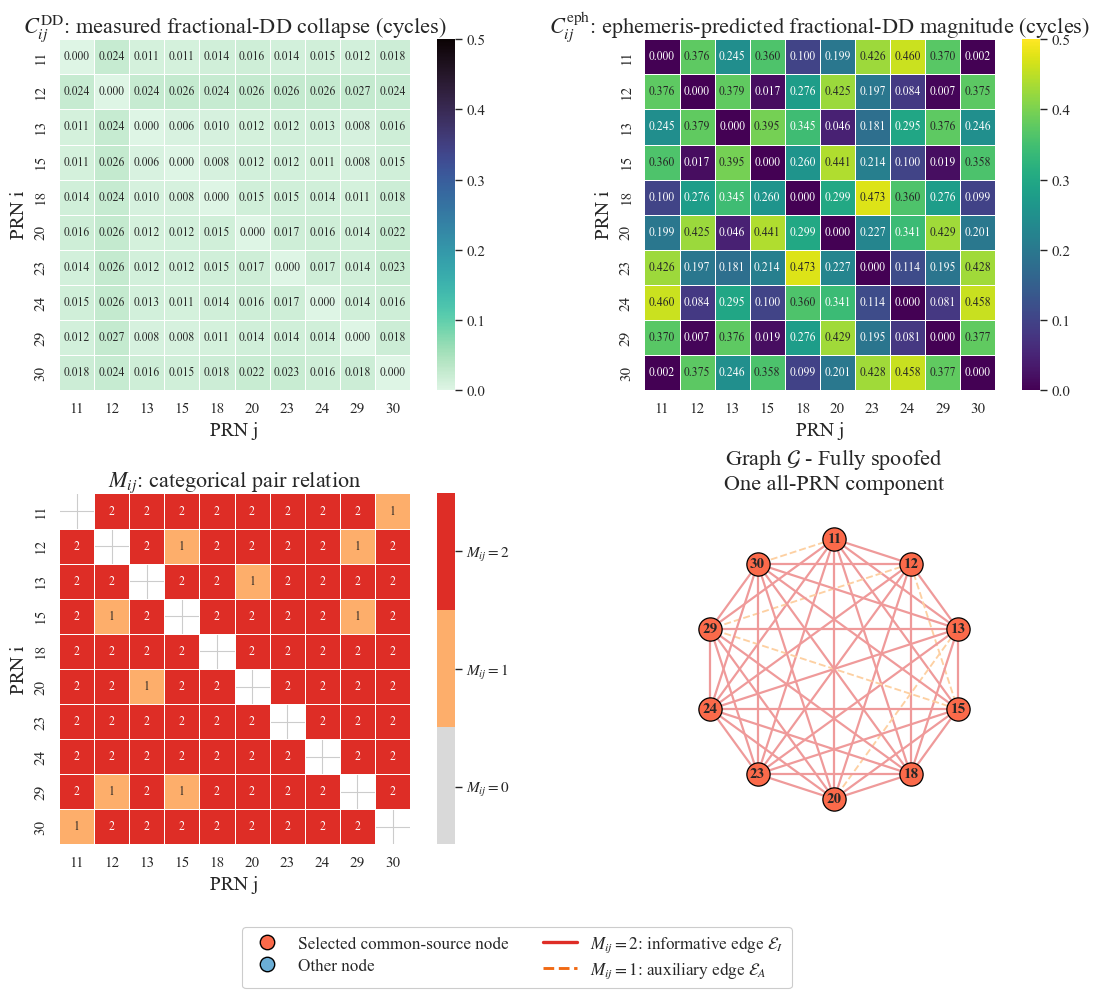

In [8]:
full_result = results["Full spoof"]
print(full_result["scenario_decision"])
print("Selected group:", full_result["selected_group"])
print("Satellite availability and eligibility")
display(full_result["availability"])
print("Node relations and graph degree")
display(full_result["node_summary"])
print("Connected-component validation")
display(full_result["component_summary"].round(5))
print(f"Every pair relation; orange rows have predicted phase separation below {EPHEMERIS_FRACTIONAL_DD_NONCOLLAPSE_THRESHOLD_CYCLES:g} cycles")
display(full_result["pairs"][[
    "pair", "median_fractional_dd_collapse_cycles",
    "median_ephemeris_predicted_pair_separation_cycles",
    "median_ephemeris_aoa_separation_deg",
    "relation_code", "specific_node_relation", "epoch_count",
]].sort_values(["relation_code", "median_fractional_dd_collapse_cycles"], ascending=[False, True]).round(5))
plot_scenario_evidence(full_result)

# 11. Scenario C - Mixed-tracking recording

Let $\mathcal V_{\mathrm{CS}}\subset\mathcal V$ be counterfeit signals from one physical transmitter. Their internal pairs should satisfy

$$
C_{ij}^{\mathrm{DD}}\simeq0,
\qquad i,j\in\mathcal V_{\mathrm{CS}},
$$

while pairs involving distinct physical sources generally do not collapse. Informative edges $\mathcal E_I$ nominate the candidate component; auxiliary edges $\mathcal E_A$ may support its complete internal consistency but cannot independently nominate vertices.

The expected journal-level decision is

$$
\varnothing\neq\widehat{\mathcal V}_{\mathrm{CS}}\subset\mathcal V
\quad\Longrightarrow\quad
\widehat{\mathcal H}=\mathcal H_M.
$$

One strict PRN subset forms a corroborated common-signature component
Selected group: (6, 9, 11, 20)
Satellite availability and eligibility


,svid,single_difference_epochs,ephemeris_epochs,eligible
0,6,34,30,True
1,9,34,30,True
2,10,34,34,True
3,11,34,30,True
4,12,34,34,True
5,13,34,0,False
6,15,34,34,True
7,18,34,34,True
8,20,34,30,True
9,23,34,34,True


Node relations and graph degree


,svid,fractional_dd_collapse_degree,informative_common_source_degree,predicted_phase_aliased_collapse_degree,selected_common_source_member,graph_evidence_status
0,6,3,2,1,True,corroborated_group_member
1,9,3,3,0,True,corroborated_group_member
2,10,0,0,0,False,not_assigned_to_detected_group
3,11,3,3,0,True,corroborated_group_member
4,12,0,0,0,False,not_assigned_to_detected_group
5,15,0,0,0,False,not_assigned_to_detected_group
6,18,0,0,0,False,not_assigned_to_detected_group
7,20,3,2,1,True,corroborated_group_member
8,23,0,0,0,False,not_assigned_to_detected_group
9,24,0,0,0,False,not_assigned_to_detected_group


Connected-component validation


,component_id,component_svids,component_size,possible_pair_count,observed_pair_count,observed_pair_coverage,collapse_pair_count,collapse_fraction_observed,informative_pair_count,noncollapse_pair_count,corroborated_common_signature_group,rejection_reasons
0,1,"(6, 9, 11, 20)",4,6,6,1.0,6,1.0,5,0,True,()


Specific relations inside the discovered common-source component


,pair,median_fractional_dd_collapse_cycles,median_ephemeris_predicted_pair_separation_cycles,median_ephemeris_aoa_separation_deg,relation_code,specific_node_relation,epoch_count
30,PRN 11–PRN 20,0.00302,0.33508,21.37927,2.0,M_ij=2: informative edge in E_I,30
2,PRN 6–PRN 11,0.01033,0.33192,21.19204,2.0,M_ij=2: informative edge in E_I,30
0,PRN 6–PRN 9,0.01072,0.09522,5.58202,2.0,M_ij=2: informative edge in E_I,30
11,PRN 9–PRN 11,0.00439,0.42713,26.77406,2.0,M_ij=2: informative edge in E_I,30
15,PRN 9–PRN 20,0.00390,0.09206,5.39479,2.0,M_ij=2: informative edge in E_I,30
6,PRN 6–PRN 20,0.01082,0.00316,0.18723,1.0,M_ij=1: auxiliary edge in E_A,30


All mixed-case pair relations


,pair,median_fractional_dd_collapse_cycles,median_ephemeris_predicted_pair_separation_cycles,median_ephemeris_aoa_separation_deg,relation_code,specific_node_relation,epoch_count
30,PRN 11–PRN 20,0.00302,0.33508,21.37927,2.0,M_ij=2: informative edge in E_I,30
15,PRN 9–PRN 20,0.00390,0.09206,5.39479,2.0,M_ij=2: informative edge in E_I,30
11,PRN 9–PRN 11,0.00439,0.42713,26.77406,2.0,M_ij=2: informative edge in E_I,30
2,PRN 6–PRN 11,0.01033,0.33192,21.19204,2.0,M_ij=2: informative edge in E_I,30
0,PRN 6–PRN 9,0.01072,0.09522,5.58202,2.0,M_ij=2: informative edge in E_I,30
6,PRN 6–PRN 20,0.01082,0.00316,0.18723,1.0,M_ij=1: auxiliary edge in E_A,30
44,PRN 15–PRN 32,0.03672,0.17971,10.97398,0.0,M_ij=0: measured fractional DD not collapsed,33
37,PRN 12–PRN 23,0.03841,0.25055,44.15019,0.0,M_ij=0: measured fractional DD not collapsed,34
46,PRN 18–PRN 23,0.04061,0.07138,65.20183,0.0,M_ij=0: measured fractional DD not collapsed,34
40,PRN 15–PRN 18,0.05531,0.05619,64.23397,0.0,M_ij=0: measured fractional DD not collapsed,34


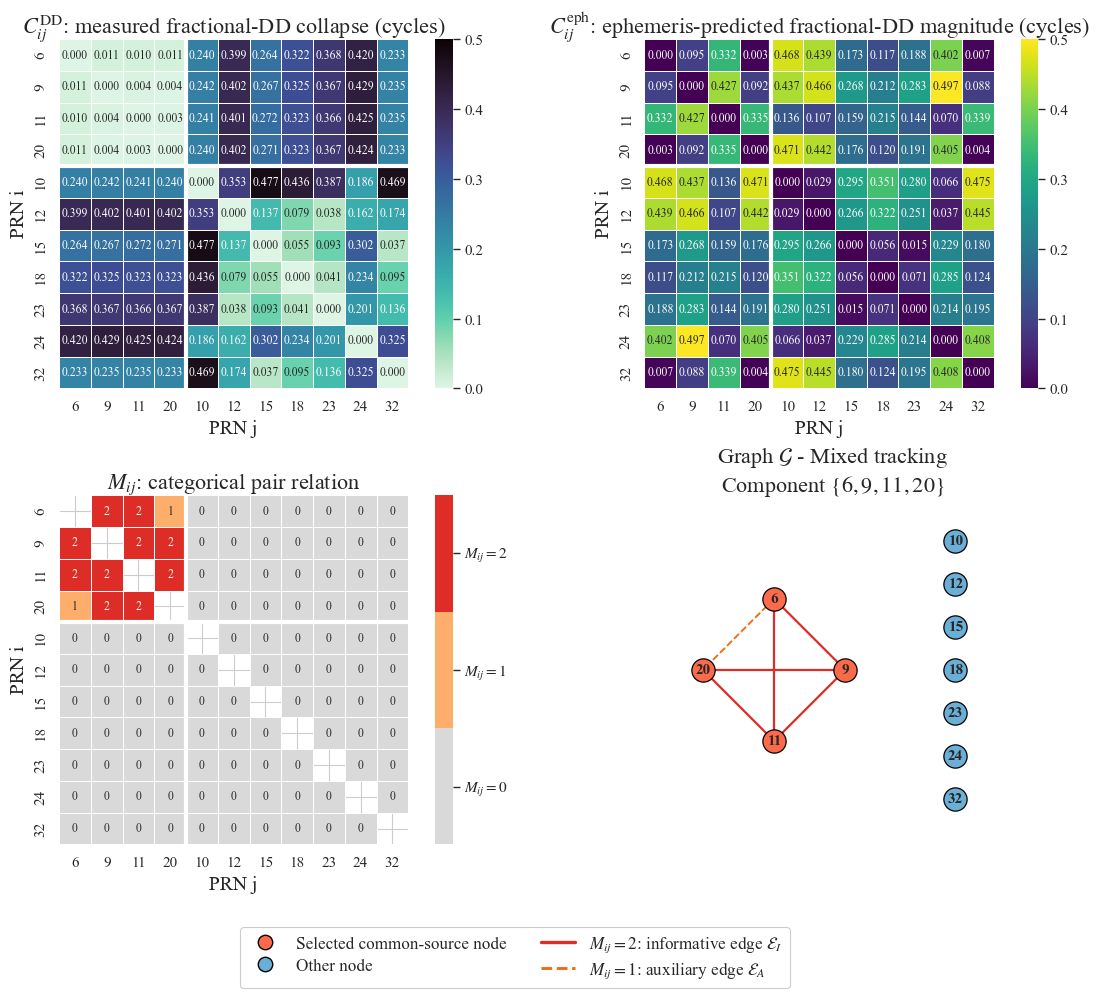

In [9]:
mixed_result = results["Mixed tracking"]
print(mixed_result["scenario_decision"])
print("Selected group:", mixed_result["selected_group"])
print("Satellite availability and eligibility")
display(mixed_result["availability"])
print("Node relations and graph degree")
display(mixed_result["node_summary"])
print("Connected-component validation")
display(mixed_result["component_summary"].round(5))

selected_set = set(mixed_result["selected_group"])
mixed_internal_pairs = mixed_result["pairs"].loc[
    mixed_result["pairs"].left_svid.isin(selected_set)
    & mixed_result["pairs"].right_svid.isin(selected_set)
].copy()
print("Specific relations inside the discovered common-source component")
display(mixed_internal_pairs[[
    "pair", "median_fractional_dd_collapse_cycles",
    "median_ephemeris_predicted_pair_separation_cycles",
    "median_ephemeris_aoa_separation_deg",
    "relation_code", "specific_node_relation", "epoch_count",
]].sort_values(["relation_code", "pair"], ascending=[False, True]).round(5))

print("All mixed-case pair relations")
display(mixed_result["pairs"][[
    "pair", "median_fractional_dd_collapse_cycles",
    "median_ephemeris_predicted_pair_separation_cycles",
    "median_ephemeris_aoa_separation_deg",
    "relation_code", "specific_node_relation", "epoch_count",
]].sort_values(["relation_code", "median_fractional_dd_collapse_cycles"], ascending=[False, True]).round(5))
plot_scenario_evidence(mixed_result)

## 12. Representative measured fractional-DD traces

The three separate figures show representative $\Phi_{ij,k}^{\mathrm{DD}}$ traces:

- **Authentic:** three non-overlapping pairs with the largest 10th percentile of $|\Phi_{ij,k}^{\mathrm{DD}}|$;
- **Fully spoofed:** three non-overlapping pairs with the smallest 90th percentile of $|\Phi_{ij,k}^{\mathrm{DD}}|$;
- **Mixed tracking:** one stable counterfeit-counterfeit collapse and the most divergent counterfeit-authentic and authentic-authentic examples.

Known mixed-recording identities are used only to select and label this post-hoc illustration; they are not passed to the graph detector. The shaded band is the fixed collapse region $|\Phi_{ij,k}^{\mathrm{DD}}|\leq\tau_c$.

,scenario,pair_class,pair,median_abs_fractional_dd_cycles,q10_abs_fractional_dd_cycles,q90_abs_fractional_dd_cycles,epoch_count
0,Authentic,authentic-authentic,PRN 10-PRN 23,0.4511,0.3963,0.4809,119
1,Authentic,authentic-authentic,PRN 15-PRN 32,0.4531,0.3906,0.4896,120
2,Authentic,authentic-authentic,PRN 5-PRN 24,0.2555,0.2090,0.3034,117
3,Full spoof,counterfeit-counterfeit,PRN 13-PRN 15,0.0061,0.0014,0.0134,120
4,Full spoof,counterfeit-counterfeit,PRN 11-PRN 29,0.0119,0.0023,0.0269,120
5,Full spoof,counterfeit-counterfeit,PRN 18-PRN 23,0.0147,0.0030,0.0348,120
6,Mixed tracking,counterfeit-counterfeit,PRN 9-PRN 20,0.0039,0.0007,0.0104,30
7,Mixed tracking,counterfeit-authentic,PRN 11-PRN 24,0.4247,0.3937,0.4641,30
8,Mixed tracking,authentic-authentic,PRN 10-PRN 15,0.4767,0.4570,0.4948,34


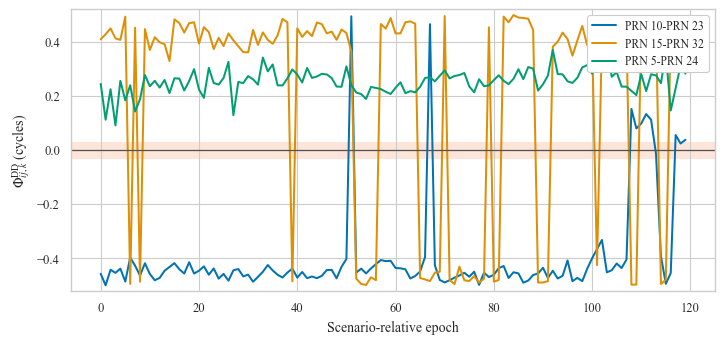

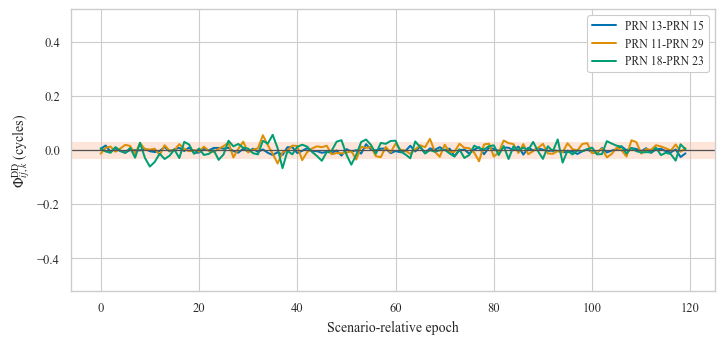

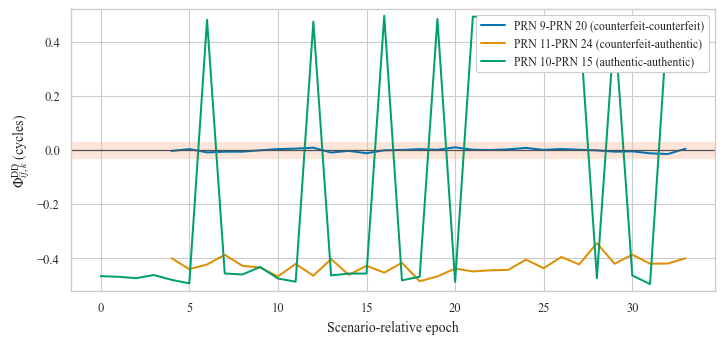

Exported trace figures:
/Users/betty/Desktop/fractional_dd_authentic.png
/Users/betty/Desktop/fractional_dd_authentic.eps
/Users/betty/Desktop/fractional_dd_authentic.pdf
/Users/betty/Desktop/fractional_dd_authentic.svg
/Users/betty/Desktop/fractional_dd_full_spoof.png
/Users/betty/Desktop/fractional_dd_full_spoof.eps
/Users/betty/Desktop/fractional_dd_full_spoof.pdf
/Users/betty/Desktop/fractional_dd_full_spoof.svg
/Users/betty/Desktop/fractional_dd_mixed_tracking.png
/Users/betty/Desktop/fractional_dd_mixed_tracking.eps
/Users/betty/Desktop/fractional_dd_mixed_tracking.pdf
/Users/betty/Desktop/fractional_dd_mixed_tracking.svg


In [10]:
MIXED_KNOWN_COUNTERFEIT_SVIDS = frozenset({6, 9, 11, 20})

def summarize_pair_traces(result):
    rows = []
    for (left, right), trace in result["epoch_pairs"].groupby(["left_svid", "right_svid"]):
        magnitude = trace["fractional_dd_cycles"].abs().dropna()
        if len(magnitude) < MIN_PAIR_EPOCHS:
            continue
        rows.append({
            "left_svid": int(left),
            "right_svid": int(right),
            "pair": f"PRN {int(left)}-PRN {int(right)}",
            "median_abs_fractional_dd_cycles": float(magnitude.median()),
            "q10_abs_fractional_dd_cycles": float(magnitude.quantile(0.10)),
            "q90_abs_fractional_dd_cycles": float(magnitude.quantile(0.90)),
            "epoch_count": int(len(magnitude)),
        })
    return pd.DataFrame(rows)

def select_nonoverlapping_pairs(scores, score_column, ascending, count=3):
    ranked = scores.sort_values(
        [score_column, "left_svid", "right_svid"],
        ascending=[ascending, True, True],
    )
    selected_rows = []
    used_svids = set()
    for row in ranked.itertuples(index=False):
        if row.left_svid in used_svids or row.right_svid in used_svids:
            continue
        selected_rows.append(row._asdict())
        used_svids.update((row.left_svid, row.right_svid))
        if len(selected_rows) == count:
            break
    return pd.DataFrame(selected_rows)

authentic_scores = summarize_pair_traces(authentic_result)
full_scores = summarize_pair_traces(full_result)
mixed_scores = summarize_pair_traces(mixed_result)

authentic_selected = select_nonoverlapping_pairs(
    authentic_scores, "q10_abs_fractional_dd_cycles", ascending=False
).assign(pair_class="authentic-authentic")
full_selected = select_nonoverlapping_pairs(
    full_scores, "q90_abs_fractional_dd_cycles", ascending=True
).assign(pair_class="counterfeit-counterfeit")

def mixed_pair_class(row):
    left_counterfeit = row.left_svid in MIXED_KNOWN_COUNTERFEIT_SVIDS
    right_counterfeit = row.right_svid in MIXED_KNOWN_COUNTERFEIT_SVIDS
    if left_counterfeit and right_counterfeit:
        return "counterfeit-counterfeit"
    if left_counterfeit or right_counterfeit:
        return "counterfeit-authentic"
    return "authentic-authentic"

mixed_scores["pair_class"] = mixed_scores.apply(mixed_pair_class, axis=1)
mixed_selection_rows = []
for pair_class, score_column, ascending in (
    ("counterfeit-counterfeit", "q90_abs_fractional_dd_cycles", True),
    ("counterfeit-authentic", "q10_abs_fractional_dd_cycles", False),
    ("authentic-authentic", "q10_abs_fractional_dd_cycles", False),
):
    candidate = mixed_scores.loc[mixed_scores.pair_class.eq(pair_class)].sort_values(
        [score_column, "left_svid", "right_svid"],
        ascending=[ascending, True, True],
    ).iloc[0]
    mixed_selection_rows.append(candidate.to_dict())
mixed_selected = pd.DataFrame(mixed_selection_rows)

selection_table = pd.concat([
    authentic_selected.assign(scenario="Authentic"),
    full_selected.assign(scenario="Full spoof"),
    mixed_selected.assign(scenario="Mixed tracking"),
], ignore_index=True)
display(selection_table[[
    "scenario", "pair_class", "pair",
    "median_abs_fractional_dd_cycles",
    "q10_abs_fractional_dd_cycles",
    "q90_abs_fractional_dd_cycles", "epoch_count",
]].round(4))

def plot_selected_fractional_dd(ax, result, selected_pairs):
    epoch_pairs = result["epoch_pairs"]
    epoch_order = {
        epoch: position
        for position, epoch in enumerate(sorted(epoch_pairs["epoch_index"].dropna().unique()))
    }
    colors = sns.color_palette("colorblind", n_colors=len(selected_pairs))
    for color, row in zip(colors, selected_pairs.itertuples(index=False)):
        trace = epoch_pairs.loc[
            epoch_pairs.left_svid.eq(row.left_svid)
            & epoch_pairs.right_svid.eq(row.right_svid)
        ].sort_values("epoch_index")
        x = trace["epoch_index"].map(epoch_order)
        label = row.pair
        if result["name"] == "Mixed tracking":
            label = f"{row.pair} ({row.pair_class})"
        ax.plot(x, trace["fractional_dd_cycles"], color=color, lw=1.45, label=label)
    threshold = FRACTIONAL_DD_COLLAPSE_THRESHOLD_CYCLES
    ax.axhspan(-threshold, threshold, color="#fee5d9", zorder=0)
    ax.axhline(0.0, color="#525252", lw=0.9)
    ax.set_xlabel("Scenario-relative epoch")
    ax.set_ylim(-0.52, 0.52)
    ax.tick_params(axis="both", labelsize=9)
    ax.legend(loc="upper right", fontsize=8.5, frameon=True, framealpha=1.0)

paper_figure_specs = (
    (authentic_result, authentic_selected, "fractional_dd_authentic"),
    (full_result, full_selected, "fractional_dd_full_spoof"),
    (mixed_result, mixed_selected, "fractional_dd_mixed_tracking"),
)
exported_trace_paths = []
for result, selected_pairs, figure_stem in paper_figure_specs:
    fig, ax = plt.subplots(figsize=(FULL_WIDTH_FIGURE_IN, 3.4))
    plot_selected_fractional_dd(ax, result, selected_pairs)
    ax.set_ylabel(r"$\Phi^{\mathrm{DD}}_{ij,k}$ (cycles)")
    fig.tight_layout(pad=0.55)
    if SAVE_OUTPUTS:
        exported_trace_paths.extend(export_figure(fig, figure_stem))
    display(fig)
    plt.close(fig)

print("Exported trace figures:")
for figure_path in exported_trace_paths:
    print(figure_path)

## 13. Direct visual comparison of graph topology

The three network diagrams use the journal's identical vertex and edge semantics:

$$
\widehat{\mathcal H}=
\begin{cases}
\mathcal H_0,&\widehat{\mathcal C}=\varnothing,\\
\mathcal H_F,&\widehat{\mathcal C}=\{\mathcal V\},\\
\mathcal H_M,&\varnothing\neq\widehat{\mathcal V}_{\mathrm{CS}}\subset\mathcal V.
\end{cases}
$$

Red solid lines are informative edges $\mathcal E_I$ and orange dashed lines are auxiliary edges $\mathcal E_A$. The thresholds remain $\tau_c=0.03$ cycles and $\tau_e=0.05$ cycles.

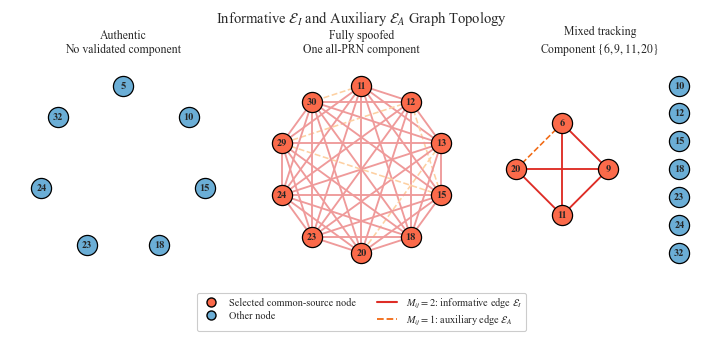

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(FULL_WIDTH_FIGURE_IN, 3.35))
for ax, result in zip(axes, results.values()):
    draw_relation_graph(
        result, ax, show_edge_labels=False, show_legend=False, compact=True,
    )
fig.suptitle(
    r"Informative $\mathcal{E}_I$ and Auxiliary $\mathcal{E}_A$ Graph Topology",
    fontsize=PUBLICATION_TITLE_SIZE_PT, y=0.985,
)
fig.legend(
    handles=graph_legend_handles(), loc="lower center", ncol=2,
    bbox_to_anchor=(0.5, 0.01), fontsize=7.4,
    frameon=True, framealpha=1.0, borderpad=0.35, labelspacing=0.3,
)
fig.tight_layout(rect=(0.0, 0.16, 1.0, 0.92), pad=0.25, w_pad=0.15)
if SAVE_OUTPUTS:
    export_figure(fig, "three_scenario_graph_comparison")
display(fig)
plt.close(fig)

In [12]:
if SAVE_OUTPUTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    scenario_comparison.to_csv(OUTPUT_DIR / "three_scenario_summary.csv", index=False)
    for name, result in results.items():
        prefix = name.lower().replace(" ", "_")
        result["availability"].to_csv(OUTPUT_DIR / f"{prefix}_availability.csv", index=False)
        result["epoch_pairs"].to_csv(OUTPUT_DIR / f"{prefix}_epoch_pair_evidence.csv", index=False)
        result["pairs"].to_csv(OUTPUT_DIR / f"{prefix}_pair_relations.csv", index=False)
        result["node_summary"].to_csv(OUTPUT_DIR / f"{prefix}_node_summary.csv", index=False)
        result["component_summary"].to_csv(OUTPUT_DIR / f"{prefix}_component_summary.csv", index=False)
    print(f"Saved graph-classifier tables and figures to {OUTPUT_DIR}")
    print(f"Saved {', '.join(FIGURE_EXPORT_FORMATS).upper()} figures to {FIGURE_EXPORT_DIR}")
else:
    print("SAVE_OUTPUTS=False; results are displayed inline and no artifacts were written.")

Saved graph-classifier tables and figures to outputs/aoa_paper/three_scenario_graph_classifier
Saved PNG, EPS, PDF, SVG figures to /Users/betty/Desktop


## 14. AOA_Paper Figure 4 design

This cell is the shared design source for the side-by-side mixed-tracking Figure 4. It keeps the serif typography and 7.2-inch publication width used above. Solid warm-colored marker traces identify declared spoof PRNs; dashed cool-colored traces identify the other PRNs. Colors stay fixed across both panels in a run. The shared legend sits above the panels. Two descriptions sit below their respective panels: **(a) Ephemeris-derived baseline-referenced angles** and **(b) Angles estimated using the proposed wrapped-DD method.** The figure height includes space for both descriptions.

`aoa_figure_report.load_figure_design()` reads only the literal dictionary in the tagged cell below, so `AOA_Paper.ipynb` can reuse this design without running the graph experiments. Edit `comparison_captions` to change the descriptions or their spacing. Only Figure 4 is exported, in PNG/PDF/SVG/EPS.

The optional `--compact-epochs 12` report uses this same design and the axis label **Epoch**. Positions 1–12 represent selected 1 Hz samples in original chronological order, with recording gaps removed from the axis. The timestamp mapping and selection policy are retained in the companion data. No smoothing or interpolation changes the observations. The optional whole-PRN error filter applies to both panels; its exclusions and supporting agreement rates remain in the report CSVs.


In [ ]:
# Shared publication design; keep this assignment a literal dictionary.
# Default: actual elapsed time. Optional compacted display retains original timestamp mappings.
# Missing phase/geometry for an individual PRN stays NaN and breaks its line.
PAPER_FIGURE_DESIGN = {'standalone_proposed_use_all_phase_epochs': True,
 'compacted_axis_label': 'Epoch',
 'elapsed_axis_label': 'Time (s)',
 'agreement_table': {'width_in': 3.5,
                     'row_height_in': 0.215,
                     'margin_in': 0.10,
                     'font_size': 10.0,
                     'horizontal_bounds': [0.035, 0.965],
                     'column_widths': [0.34, 0.22, 0.22, 0.22],
                     'outer_rule_width': 0.8,
                     'inner_rule_width': 0.45},
 'compacted_tick_step': 2,
 'single_figsize': [7.2, 3.45],
 'comparison_figsize': [7.2, 3.9],
 'comparison_captions': {'texts': ['(a) Ephemeris-derived\nbaseline-referenced angles',
                                  '(b) Angles estimated using the\nproposed wrapped-DD method.'],
                         'font_size': 10.0,
                         'bottom_in': 0.10,
                         'gap_in': 0.10},
 'formats': ['png', 'pdf', 'svg', 'eps'],
 'dpi': 300,
 'legend_columns': 4,
 'spoof_colors': ['#c62828', '#e67500', '#8e3293', '#bd5265'],
 'authentic_colors': ['#226b91',
                      '#44846a',
                      '#5b75a7',
                      '#698e9b',
                      '#667859',
                      '#4f5e81',
                      '#2b8587',
                      '#8992a8'],
 'spoof_markers': ['o', 's', '^', 'D'],
 'spoof_linewidth': 1.6,
 'authentic_linewidth': 1.0,
 'markersize': 3.0,
 'grid_color': '#dedede',
 'rc_params': {'font.family': 'serif',
               'font.serif': ['Times New Roman', 'Times', 'DejaVu Serif'],
               'mathtext.fontset': 'stix',
               'font.size': 10.0,
               'axes.titlesize': 9.5,
               'axes.labelsize': 10.0,
               'xtick.labelsize': 8.5,
               'ytick.labelsize': 8.5,
               'legend.fontsize': 8.0,
               'figure.titlesize': 10.5,
               'axes.facecolor': 'white',
               'figure.facecolor': 'white',
               'axes.edgecolor': '#505050',
               'axes.linewidth': 0.65,
               'savefig.dpi': 300,
               'savefig.bbox': None,
               'pdf.fonttype': 42,
               'ps.fonttype': 42},
 'legend_anchor': [0.5, 1.0],
 'legend_gap_in': 0.08,
 'subplot_margins': {'left': 0.085, 'right': 0.985, 'bottom': 0.15, 'wspace': 0.12}}


### Report figures and reproduction

1. `figure_01_fractional_double_difference_mixed`: all valid non-reference fractional-DD traces.
2. `figure_02_alpha_i_ephemeris_mixed`: baseline-relative Receiver 1 NAV-SAT AoA.
3. `figure_03_alpha_i_proposed_best_m_mixed`: joint-source branches for spoof PRNs and ephemeris-aligned constant branches for authentic PRNs.
4. `figure_04_alpha_i_side_by_side_best_m`: identical PRNs, paired-valid epochs, colors, and 0–180° limits for the two methods.

The plot implementation is shared in `aoa_figure_report.py`; the data and branch choices come from `AOA_Paper.ipynb`. No curve is interpolated. The README files and manifests record the branch selection and the use of ephemeris to select authentic branches for the manuscript captions. Figure 04 shows ephemeris on the left and proposed DD on the right, without panel titles.

Run all four captures from the project root:

```bash
uv run python run_aoa_figure_report.py
```

This executes the paper notebook once per capture and exports PNG, PDF, SVG, and EPS into `~/Desktop/AOA_Figure_Report_sp-partial-28-08/{v4,v5,v8,v9}/`, alongside an executed notebook, the plotted CSVs, and a manifest. The spoof groups are read from each capture's `note.txt`. v4 declares m = 0; v5 declares m = −1 (approximately +143°). v8/v9 use reversed receiver order and retain the unresolved joint-source branch choice. To generate one capture interactively, set `DATASET_DIR` in `AOA_Paper.ipynb` and run all its cells.
